In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected")

PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/captions.json
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000487632.jpg
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000203982.jpg
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000447520.jpg
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000316443.jpg
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000464415.jpg
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000368731.jpg
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000462131.jpg
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train201

In [3]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".json"):
            print(os.path.join(root, file))

/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/captions.json


In [20]:
import os
import json

# Automatically find captions.json
json_files = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower() == "captions.json":
            json_files.append(os.path.join(root, file))

print("Found JSON files:")
for path in json_files:
    print(path)

# Use the first captions.json found
json_path = json_files[0]

print("\nUsing:")
print(json_path)

# Load captions
with open(json_path, "r") as f:
    data = json.load(f)

print("\nData type:", type(data))
print("Number of entries:", len(data))

print("\nFirst entry:")
if isinstance(data, dict):
    first_key = next(iter(data))
    print("Key:", first_key)
    print("Value:", data[first_key])
else:
    print(data[0])

Found JSON files:
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/captions.json

Using:
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/captions.json

Data type: <class 'list'>
Number of entries: 93950

First entry:
{'image_id': 299675, 'id': 328, 'caption': 'A white square kitchen with tile floor that needs repairs '}


In [21]:
import os

print("Folders/files inside the dataset:\n")

base = "/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning"

for item in os.listdir(base):
    path = os.path.join(base, item)
    if os.path.isdir(path):
        print("FOLDER:", item)
    else:
        print("FILE:", item)

Folders/files inside the dataset:

FILE: captions.json
FOLDER: Images


In [24]:
import os

print("\nImage files found:\n")

count = 0

for root, dirs, files in os.walk("/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning"):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            print(os.path.join(root, file))
            count += 1

            if count >= 10:
                break

    if count >= 10:
        break

print("\nFirst 10 images found:", count)


Image files found:

/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000487632.jpg
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000203982.jpg
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000447520.jpg
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000316443.jpg
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000464415.jpg
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000368731.jpg
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000462131.jpg
/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000211807.jpg
/kaggle/input/datasets/nagasai524/mini-coco2014-dat

In [25]:
import os
import json
import re
import random
from collections import Counter, defaultdict

import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

# ============================================================
# 1. Paths
# ============================================================

BASE_DIR = "/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning"

CAPTION_FILE = os.path.join(BASE_DIR, "captions.json")
IMAGE_DIR = os.path.join(BASE_DIR, "Images")

# ============================================================
# 2. Load captions
# ============================================================

with open(CAPTION_FILE, "r") as f:
    caption_data = json.load(f)

print("Total caption records:", len(caption_data))

# Group captions by image_id
image_captions = defaultdict(list)

for item in caption_data:
    image_id = item["image_id"]
    caption = item["caption"].strip()
    image_captions[image_id].append(caption)

print("Unique images in captions:", len(image_captions))

# ============================================================
# 3. Find image files
# ============================================================

image_paths = {}

for filename in os.listdir(IMAGE_DIR):
    if filename.lower().endswith((".jpg", ".jpeg", ".png")):

        # Example:
        # COCO_train2014_000000487632.jpg
        match = re.search(r"(\d+)\.(jpg|jpeg|png)$", filename.lower())

        if match:
            image_id = int(match.group(1))
            image_paths[image_id] = os.path.join(IMAGE_DIR, filename)

print("Images found:", len(image_paths))

# ============================================================
# 4. Keep only images having captions AND image files
# ============================================================

valid_image_ids = [
    image_id
    for image_id in image_captions
    if image_id in image_paths
]

print("Images with both captions and image files:", len(valid_image_ids))

# ============================================================
# 5. Train / validation split
# ============================================================

random.seed(42)
random.shuffle(valid_image_ids)

split_index = int(0.9 * len(valid_image_ids))

train_ids = valid_image_ids[:split_index]
val_ids = valid_image_ids[split_index:]

print("Training images:", len(train_ids))
print("Validation images:", len(val_ids))

# ============================================================
# 6. Tokenizer
# ============================================================

def tokenize(sentence):
    sentence = sentence.lower()
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", sentence)
    return tokens

# ============================================================
# 7. Build vocabulary
# ============================================================

MIN_FREQ = 5

counter = Counter()

for image_id in train_ids:
    for caption in image_captions[image_id]:
        counter.update(tokenize(caption))

# Special tokens
special_tokens = [
    "<PAD>",
    "<START>",
    "<END>",
    "<UNK>"
]

word_to_idx = {}

for i, token in enumerate(special_tokens):
    word_to_idx[token] = i

for word, frequency in counter.items():
    if frequency >= MIN_FREQ:
        word_to_idx[word] = len(word_to_idx)

idx_to_word = {idx: word for word, idx in word_to_idx.items()}

print("Vocabulary size:", len(word_to_idx))

# ============================================================
# 8. Convert caption to numbers
# ============================================================

MAX_LENGTH = 20

def numericalize_caption(caption):

    tokens = tokenize(caption)

    tokens = (
        ["<START>"]
        + tokens[:MAX_LENGTH - 2]
        + ["<END>"]
    )

    numerical_caption = [
        word_to_idx.get(token, word_to_idx["<UNK>"])
        for token in tokens
    ]

    # Padding
    while len(numerical_caption) < MAX_LENGTH:
        numerical_caption.append(word_to_idx["<PAD>"])

    return numerical_caption[:MAX_LENGTH]

# ============================================================
# 9. PyTorch Dataset
# ============================================================

class CocoCaptionDataset(Dataset):

    def __init__(self, image_ids, transform=None):
        self.image_ids = image_ids
        self.transform = transform

        # Create one sample for every image-caption pair
        self.samples = []

        for image_id in image_ids:
            for caption in image_captions[image_id]:
                self.samples.append((image_id, caption))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        image_id, caption = self.samples[index]

        image_path = image_paths[image_id]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        caption = torch.tensor(
            numericalize_caption(caption),
            dtype=torch.long
        )

        return image, caption


# ============================================================
# 10. Image transformation
# ============================================================

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ============================================================
# 11. Create datasets
# ============================================================

train_dataset = CocoCaptionDataset(
    train_ids,
    transform=transform
)

val_dataset = CocoCaptionDataset(
    val_ids,
    transform=transform
)

print("\nTraining samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

# ============================================================
# 12. DataLoaders
# ============================================================

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\nDataLoader ready!")

# ============================================================
# 13. Test one batch
# ============================================================

images, captions = next(iter(train_loader))

print("\nBatch test:")
print("Images shape:", images.shape)
print("Captions shape:", captions.shape)

Total caption records: 93950
Unique images in captions: 18783
Images found: 18783
Images with both captions and image files: 18783
Training images: 16904
Validation images: 1879
Vocabulary size: 4308

Training samples: 84553
Validation samples: 9397

DataLoader ready!

Batch test:
Images shape: torch.Size([32, 3, 224, 224])
Captions shape: torch.Size([32, 20])


In [30]:
import torch
import torch.nn as nn
from torchvision import models

# ============================================================
# Device
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

# ============================================================
# Encoder CNN - VGG16
# ============================================================

class EncoderCNN(nn.Module):

    def __init__(self, embed_size=512):
        super().__init__()

        # Load pretrained VGG16
        vgg = models.vgg16(
            weights=models.VGG16_Weights.DEFAULT
        )

        # Keep convolutional layers
        self.features = vgg.features

        # Freeze CNN parameters
        for param in self.features.parameters():
            param.requires_grad = False

        # VGG16 classifier
        self.fc = nn.Sequential(
            vgg.classifier[0],   # 25088 -> 4096
            vgg.classifier[1],   # ReLU
            vgg.classifier[2],   # Dropout
            vgg.classifier[3],   # 4096 -> 4096
            vgg.classifier[4]    # ReLU
        )

        # Convert 4096-dimensional feature to 512
        self.embed = nn.Linear(4096, embed_size)

    def forward(self, images):

        # CNN feature extraction
        features = self.features(images)

        # Flatten
        features = features.view(features.size(0), -1)

        # Fully connected layers
        features = self.fc(features)

        # Image embedding
        features = self.embed(features)

        return features


# ============================================================
# Decoder LSTM
# ============================================================

class DecoderLSTM(nn.Module):

    def __init__(
        self,
        embed_size,
        hidden_size,
        vocab_size,
        max_length=20
    ):
        super().__init__()

        self.embed_size = embed_size
        self.hidden_size = hidden_size
        self.vocab_size = vocab_size
        self.max_length = max_length

        # Word embedding
        self.word_embedding = nn.Embedding(
            vocab_size,
            embed_size
        )

        # LSTM
        self.lstm = nn.LSTM(
            input_size=embed_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        # Convert LSTM output to vocabulary scores
        self.linear = nn.Linear(
            hidden_size,
            vocab_size
        )

    def forward(self, image_features, captions):

        # Convert words to embeddings
        embeddings = self.word_embedding(captions)

        # Image is used to initialize the LSTM state
        h0 = image_features.unsqueeze(0)

        c0 = torch.zeros_like(h0)

        # LSTM
        outputs, _ = self.lstm(
            embeddings,
            (h0, c0)
        )

        # Vocabulary predictions
        outputs = self.linear(outputs)

        return outputs


# ============================================================
# Complete Show and Tell model
# ============================================================

class ShowAndTell(nn.Module):

    def __init__(
        self,
        embed_size,
        hidden_size,
        vocab_size,
        max_length=20
    ):
        super().__init__()

        self.encoder = EncoderCNN(
            embed_size
        )

        self.decoder = DecoderLSTM(
            embed_size,
            hidden_size,
            vocab_size,
            max_length
        )

    def forward(self, images, captions):

        # Extract image features
        image_features = self.encoder(images)

        # Generate caption predictions
        outputs = self.decoder(
            image_features,
            captions
        )

        return outputs


# ============================================================
# Create model
# ============================================================

EMBED_SIZE = 512
HIDDEN_SIZE = 512
VOCAB_SIZE = len(word_to_idx)

model = ShowAndTell(
    embed_size=EMBED_SIZE,
    hidden_size=HIDDEN_SIZE,
    vocab_size=VOCAB_SIZE,
    max_length=MAX_LENGTH
)

model = model.to(device)

print("\nModel created successfully!")
print("Vocabulary size:", VOCAB_SIZE)
print("Embedding size:", EMBED_SIZE)
print("LSTM hidden size:", HIDDEN_SIZE)

Using device: cuda

Model created successfully!
Vocabulary size: 4308
Embedding size: 512
LSTM hidden size: 512


In [31]:
# Get one batch
images, captions = next(iter(train_loader))

images = images.to(device)
captions = captions.to(device)

# Test forward pass
with torch.no_grad():
    outputs = model(images, captions)

print("Images:", images.shape)
print("Captions:", captions.shape)
print("Model output:", outputs.shape)

Images: torch.Size([32, 3, 224, 224])
Captions: torch.Size([32, 20])
Model output: torch.Size([32, 20, 4308])


In [56]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.auto import tqdm

# ============================================================
# Training settings
# ============================================================

NUM_EPOCHS = 2
LEARNING_RATE = 0.0001

# Ignore <PAD> when calculating loss
criterion = nn.CrossEntropyLoss(
    ignore_index=word_to_idx["<PAD>"]
)

# Trainable parameters
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE
)

print("Training configuration:")
print("Epochs:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Device:", device)

Training configuration:
Epochs: 2
Learning rate: 0.0001
Device: cuda


In [61]:
# ============================================================
# Training loop
# ============================================================

model.train()

for epoch in range(NUM_EPOCHS):

    total_loss = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS}"
    )

    for images, captions in progress_bar:

        images = images.to(device, non_blocking=True)
        captions = captions.to(device, non_blocking=True)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images, captions)

        # Predict the NEXT word
        #
        # Input:
        # <START> a dog is ...
        #
        # Target:
        # a dog is running ...
        #
        loss = criterion(
            outputs[:, :-1, :].reshape(-1, VOCAB_SIZE),
            captions[:, 1:].reshape(-1)
        )

        # Backpropagation
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        # Update weights
        optimizer.step()

        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    average_loss = total_loss / len(train_loader)

    print(
        f"\nEpoch {epoch + 1}/{NUM_EPOCHS} "
        f"- Average Loss: {average_loss:.4f}"
    )

print("\nTraining completed!")

Epoch 1/2:   0%|          | 0/2643 [00:00<?, ?it/s]


Epoch 1/2 - Average Loss: 2.7781


Epoch 2/2:   0%|          | 0/2643 [00:00<?, ?it/s]


Epoch 2/2 - Average Loss: 2.7217

Training completed!


In [63]:
# Save trained model

MODEL_PATH = "/kaggle/working/show_and_tell_pytorch.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "word_to_idx": word_to_idx,
    "idx_to_word": idx_to_word,
    "vocab_size": VOCAB_SIZE,
    "embed_size": EMBED_SIZE,
    "hidden_size": HIDDEN_SIZE,
    "max_length": MAX_LENGTH
}, MODEL_PATH)

print("Model saved successfully!")
print(MODEL_PATH)

Model saved successfully!
/kaggle/working/show_and_tell_pytorch.pth


Image: /kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning/Images/COCO_train2014_000000368409.jpg


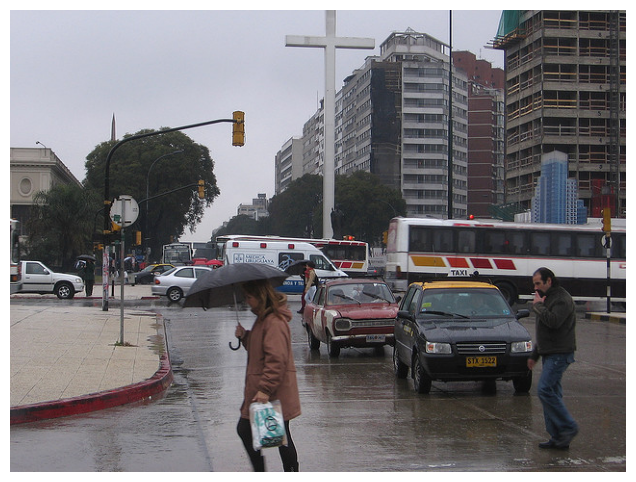


Reference captions:
- Person holding an umbrella crossing a city street in the rain.
- A women who is walking across the street while holding an umbrella.
- A woman with a black umbrella is crossing a busy street.in the rain.
- A TALL CROSS BY THE STREET IN A BIG CITY
- A couple of people crossing a street in front of cars.


In [65]:
import random
from PIL import Image
import matplotlib.pyplot as plt

# Pick a random validation image
image_id = random.choice(val_ids)

image_path = image_paths[image_id]

print("Image:", image_path)

# Load image
image = Image.open(image_path).convert("RGB")

# Display image
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

# Show the real COCO captions
print("\nReference captions:")

for caption in image_captions[image_id]:
    print("-", caption)

GENERATED CAPTION
a man is standing in the snow with a snowboard

REFERENCE CAPTIONS
- A bed sitting next to a keyboard on a white table.
- A travel table is holding all the necessities for a home music studio.
- A computer and a bed in a room together.
- The bedroom has a desk with a laptop and keyboard.
- A computer with a keyboard next to a bed.


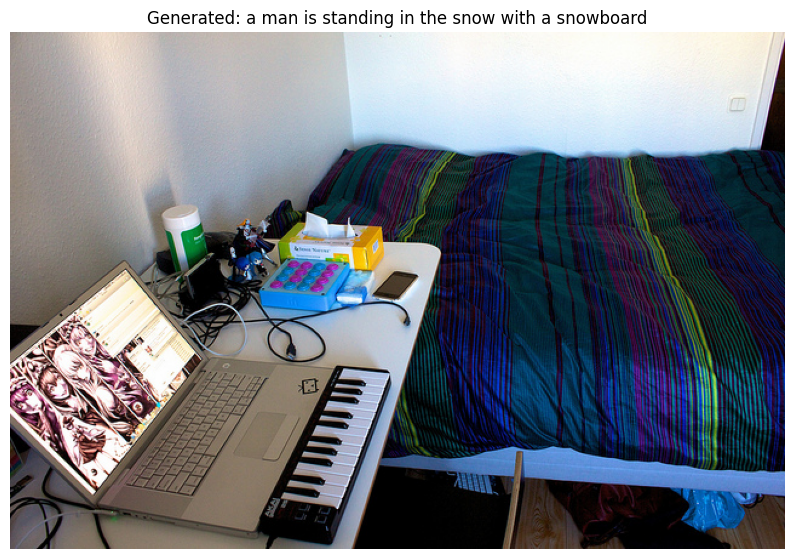

In [67]:
# ============================================================
# Generate caption using the trained PyTorch model
# ============================================================

import torch
import matplotlib.pyplot as plt
from PIL import Image

model.eval()

# ------------------------------------------------------------
# Select an image from validation data
# ------------------------------------------------------------

image_id = val_ids[0]

image_path = image_paths[image_id]

original_image = Image.open(image_path).convert("RGB")

# Apply the same preprocessing used during training
input_image = transform(original_image).unsqueeze(0).to(device)

# ------------------------------------------------------------
# Generate caption
# ------------------------------------------------------------

start_id = word_to_idx["<START>"]
end_id = word_to_idx["<END>"]

generated_words = []

with torch.no_grad():

    # Encode image
    image_features = model.encoder(input_image)

    # Initialize LSTM
    h = image_features.unsqueeze(0)

    c = torch.zeros_like(h)

    # Start token
    current_word = torch.tensor(
        [start_id],
        dtype=torch.long,
        device=device
    )

    for _ in range(MAX_LENGTH):

        # Word embedding
        embedding = model.decoder.word_embedding(
            current_word
        ).unsqueeze(1)

        # LSTM step
        output, (h, c) = model.decoder.lstm(
            embedding,
            (h, c)
        )

        # Vocabulary prediction
        scores = model.decoder.linear(
            output.squeeze(1)
        )

        # Select most probable word
        predicted_id = scores.argmax(
            dim=1
        ).item()

        # Stop at END
        if predicted_id == end_id:
            break

        # Ignore special tokens
        if predicted_id not in [
            word_to_idx["<PAD>"],
            start_id
        ]:
            generated_words.append(
                idx_to_word[predicted_id]
            )

        current_word = torch.tensor(
            [predicted_id],
            dtype=torch.long,
            device=device
        )

# ------------------------------------------------------------
# Result
# ------------------------------------------------------------

generated_caption = " ".join(generated_words)

print("=" * 60)
print("GENERATED CAPTION")
print("=" * 60)
print(generated_caption)

print("\nREFERENCE CAPTIONS")
print("=" * 60)

for caption in image_captions[image_id]:
    print("-", caption)

# ------------------------------------------------------------
# Display image
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))
plt.imshow(original_image)
plt.axis("off")
plt.title(
    "Generated: " + generated_caption,
    fontsize=12
)
plt.show()